In [4]:
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
df_2022 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2022.csv")
df_2023 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2023.csv")
df_2024 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2024.csv")
df_2025 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2025.csv")

combined_df = pd.concat(
    [df_2022, df_2023, df_2024, df_2025],
    ignore_index=True
)


combined_df["Timestamp"] = pd.to_datetime(
    combined_df["Timestamp"],
    format="mixed"
)


combined_df["Year"] = combined_df["Timestamp"].dt.year
combined_df["Month"] = combined_df["Timestamp"].dt.month
combined_df["Month_Name"] = combined_df["Timestamp"].dt.month_name()


cleaned_df = combined_df.copy()

cleaned_df = cleaned_df.dropna(axis=1, how="all")

cleaned_df = cleaned_df.drop(columns=["TOT-RF (mm)"])

"TOT-RF (mm)" in cleaned_df.columns

cleaned_df.shape



(1461, 21)

# 1A

In [5]:
cleaned_df.describe()

#cleaned_df[["PM2.5 (µg/m³)", "PM10 (µg/m³)"]].describe()

,Timestamp,PM2.5 (µg/m³),PM10 (µg/m³),NO (µg/m³),NO2 (µg/m³),NOx (ppb),NH3 (µg/m³),SO2 (µg/m³),CO (mg/m³),Ozone (µg/m³),Benzene (µg/m³),Toluene (µg/m³),AT (°C),RH (%),WS (m/s),WD (deg),SR (W/mt2),BP (mmHg),Year,Month
count,1461,1427.000000,1423.000000,1415.000000,1415.000000,1420.000000,1420.000000,1410.000000,1391.000000,1422.000000,1235.000000,1233.000000,1428.000000,1428.000000,1419.000000,1427.000000,1431.000000,1294.000000,1461.000000,1461.000000
mean,2024-01-01 00:00:00,127.407338,297.093969,81.266829,75.899043,109.066589,39.074373,19.848845,2.000910,27.330963,3.117516,33.677399,26.382645,60.889569,0.952611,145.896699,211.859380,843.240457,2023.500342,6.522930
min,2022-01-01 00:00:00,1.000000,1.000000,0.770000,0.800000,0.300000,0.140000,0.500000,0.030000,0.500000,0.000000,0.000000,10.760000,23.800000,0.300000,1.000000,2.000000,724.540000,2022.000000,1.000000
25%,2023-01-01 00:00:00,55.148681,171.212917,29.215000,48.820000,53.730000,25.200781,12.562500,1.370000,11.145000,0.920000,13.080000,20.251823,51.361875,0.420000,91.486667,111.500000,737.062500,2023.000000,4.000000
50%,2024-01-01 00:00:00,95.740000,285.065217,66.510000,70.700000,97.706250,36.180000,17.930000,1.800000,18.776354,1.980000,25.330000,28.420000,60.740000,0.690000,147.864583,141.100000,744.585000,2024.000000,7.000000
75%,2024-12-31 00:00:00,175.080000,405.422222,123.820312,97.335938,155.990000,51.070937,25.467135,2.431146,38.175000,4.385000,45.990000,32.595000,70.990000,1.150000,200.601042,175.520000,972.980000,2024.000000,10.000000
max,2025-12-31 00:00:00,672.880000,838.520000,389.270000,315.540000,389.080000,325.939394,167.860000,8.707407,128.920000,48.319444,206.270000,42.800000,93.830000,34.570000,359.000000,1206.134375,975.876042,2025.000000,12.000000
std,NaN,94.916341,153.284380,61.285396,39.963914,66.059530,21.863399,13.047230,0.972930,22.741624,3.807535,28.046389,7.383395,13.917819,1.782559,70.516063,255.251789,116.573266,1.118111,3.449884


In [6]:
cleaned_df.loc[cleaned_df["PM2.5 (µg/m³)"].idxmax()]

Timestamp          2024-11-18 00:00:00
PM2.5 (µg/m³)                   672.88
PM10 (µg/m³)                    838.52
NO (µg/m³)                       13.14
NO2 (µg/m³)                      96.34
NOx (ppb)                        55.16
NH3 (µg/m³)                      54.69
SO2 (µg/m³)                      17.75
CO (mg/m³)                         3.6
Ozone (µg/m³)                    12.73
Benzene (µg/m³)                  10.29
Toluene (µg/m³)                  66.45
AT (°C)                          24.38
RH (%)                           74.45
WS (m/s)                          0.65
WD (deg)                        227.88
SR (W/mt2)                      111.56
BP (mmHg)                       735.39
Year                              2024
Month                               11
Month_Name                    November
Name: 1052, dtype: object

In [ ]:
cleaned_df.loc[cleaned_df["PM2.5 (µg/m³)"].idxmin()]

Timestamp          2025-02-06 00:00:00
PM2.5 (µg/m³)                      1.0
PM10 (µg/m³)                       1.0
NO (µg/m³)                       46.43
NO2 (µg/m³)                     128.78
NOx (ppb)                         49.9
NH3 (µg/m³)                      83.14
SO2 (µg/m³)                        1.8
CO (mg/m³)                        1.19
Ozone (µg/m³)                      0.9
Benzene (µg/m³)                  26.13
Toluene (µg/m³)                   1.49
AT (°C)                          21.91
RH (%)                           49.88
WS (m/s)                         34.57
WD (deg)                          1.04
SR (W/mt2)                      193.12
BP (mmHg)                        737.0
Year                              2025
Month                                2
Month_Name                    February
Name: 1132, dtype: object

# 1B

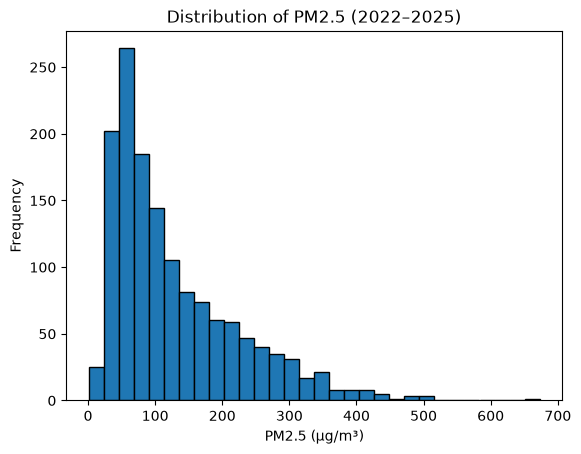

In [ ]:
plt.hist(
    cleaned_df["PM2.5 (µg/m³)"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.title("Distribution of PM2.5 (2022–2025)")
plt.show()  

# 1C

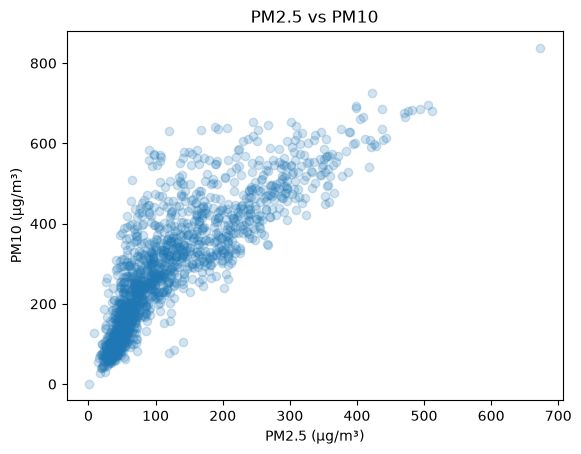

In [58]:
plt.scatter(
    cleaned_df["PM2.5 (µg/m³)"],
    cleaned_df["PM10 (µg/m³)"],
    alpha=0.2
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("PM10 (µg/m³)")
plt.title("PM2.5 vs PM10")
plt.show()

# 2A

In [54]:
cleaned_df.isnull().sum().sort_values(ascending=True)

Timestamp            0
Month_Name           0
Year                 0
Month                0
SR (W/mt2)          30
RH (%)              33
AT (°C)             33
PM2.5 (µg/m³)       34
WD (deg)            34
PM10 (µg/m³)        38
Ozone (µg/m³)       39
NOx (ppb)           41
NH3 (µg/m³)         41
WS (m/s)            42
NO (µg/m³)          46
NO2 (µg/m³)         46
SO2 (µg/m³)         51
CO (mg/m³)          70
BP (mmHg)          167
Benzene (µg/m³)    226
Toluene (µg/m³)    228
dtype: int64

In [33]:
cleaned_df = cleaned_df.dropna(axis=1, how="all")

In [34]:
cleaned_df.shape 

(1461, 21)

# 2B

In [36]:
Q1 = cleaned_df["PM2.5 (µg/m³)"].quantile(0.25)
Q3 = cleaned_df["PM2.5 (µg/m³)"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 55.14868055555556
Q3: 175.07999999999998
IQR: 119.93131944444443
Lower Bound: -124.7482986111111
Upper Bound: 354.97697916666664


In [45]:
#outliers = cleaned_df[
#    (cleaned_df["PM2.5 (µg/m³)"] < lower_bound) |
#    (cleaned_df["PM2.5 (µg/m³)"] > upper_bound)
#]

#outliers[["Timestamp", "PM2.5 (µg/m³)"]]

#outliers.shape[0]

# 2C

In [42]:
imputed_df = cleaned_df.copy()

In [43]:
pm25_median = imputed_df["PM2.5 (µg/m³)"].median()

imputed_df["PM2.5 (µg/m³)"] = (
    imputed_df["PM2.5 (µg/m³)"].fillna(pm25_median)
)

In [44]:
imputed_df["PM2.5 (µg/m³)"].isnull().sum()

np.int64(0)

# 3A

In [50]:
pm25_2022 = cleaned_df[
    cleaned_df["Year"] == 2022
]["PM2.5 (µg/m³)"].dropna()

pm25_2025 = cleaned_df[
    cleaned_df["Year"] == 2025
]["PM2.5 (µg/m³)"].dropna()

print("2022 Mean:", pm25_2022.mean())
print("2025 Mean:", pm25_2025.mean())

2022 Mean: 124.15016438356163
2025 Mean: 122.0565564738292


# 3B

In [1]:
t_stat, p_value = ttest_ind(
    pm25_2022,
    pm25_2025,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

NameError: name 'ttest_ind' is not defined

# 3C

In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is evidence of a difference in mean PM2.5 between 2022 and 2025.")
else:
    print("Fail to reject the null hypothesis")
    print("There is insufficient evidence of a difference in mean PM2.5 between 2022 and 2025.")

NameError: name 'p_value' is not defined